# P2 — Exploratory Feature Analysis (HW2 §4)

UCI Cardiotocography, Normal (label 0) vs. Pathologic (label 1). **Training portion only** (`data/splits/train.csv` through P1's `load_split("train")`); validation and test files are never opened.

All logic lives in `EDA/p2_eda.py`; this notebook runs it and displays the tables and figures. Reproduce with

```bash
pip install -r EDA/requirements.txt
python EDA/p2_eda.py                       # tables -> EDA/outputs, figures -> EDA/figures
jupyter nbconvert --to notebook --execute --inplace EDA/P2_Feature_Analysis.ipynb
```

Two uses of the training data are kept apart: descriptive EDA uses all 1076 training rows with labels; anything that imitates a one-class model (scaling, covariance, redundancy pruning) is fitted on the 972 Normal training rows only.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "EDA").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "EDA"))
import pandas as pd
from IPython.display import Image, display
import p2_eda
pd.set_option("display.max_columns", 40, "display.width", 250, "display.precision", 3)
R = p2_eda.run(verbose=False)   # seed 42, 2000 exam-level bootstrap resamples (~1 min)
df, sep = R["df"], R["sep"]

## 1. Audit of the training portion

In [2]:
print(json.dumps(R["audit"], indent=1))

{
 "n_rows": 1076,
 "n_normal": 972,
 "n_pathologic": 104,
 "anomaly_rate": 0.09665427509293681,
 "n_exams": 175,
 "n_exams_with_pathologic": 28,
 "pathologic_share_top2_exams": 0.34615384615384615,
 "pathologic_per_exam_top5": {
  "S8001034.dsp": 20,
  "S8001038.dsp": 16,
  "S7001019.dsp": 8,
  "S7001015.dsp": 6,
  "S7001023.dsp": 6
 },
 "missing_values": 0,
 "duplicate_feature_rows": 1,
 "constant_features": [],
 "near_constant_features(top value share > 0.95)": {
  "DS": 0.9935
 },
 "zero_fraction": {
  "LB": 0.0,
  "AC": 0.3745,
  "FM": 0.6403,
  "UC": 0.1004,
  "DL": 0.5325,
  "DS": 0.9935,
  "DP": 0.8968,
  "ASTV": 0.0,
  "MSTV": 0.0,
  "ALTV": 0.645,
  "MLTV": 0.0855,
  "Width": 0.0,
  "Min": 0.0,
  "Max": 0.0,
  "Nmax": 0.0483,
  "Nzeros": 0.7398,
  "Mode": 0.0,
  "Mean": 0.0,
  "Median": 0.0,
  "Variance": 0.0641,
  "Tendency": 0.5493
 },
 "n_unique": {
  "LB": 46,
  "AC": 587,
  "FM": 356,
  "UC": 788,
  "DL": 442,
  "DS": 8,
  "DP": 107,
  "ASTV": 72,
  "MSTV": 50,
  "ALTV":

## 2. Distribution contrast

Class-normalised histograms and ECDFs (each class sums to 1, so the 972 : 104 imbalance does not distort the picture).

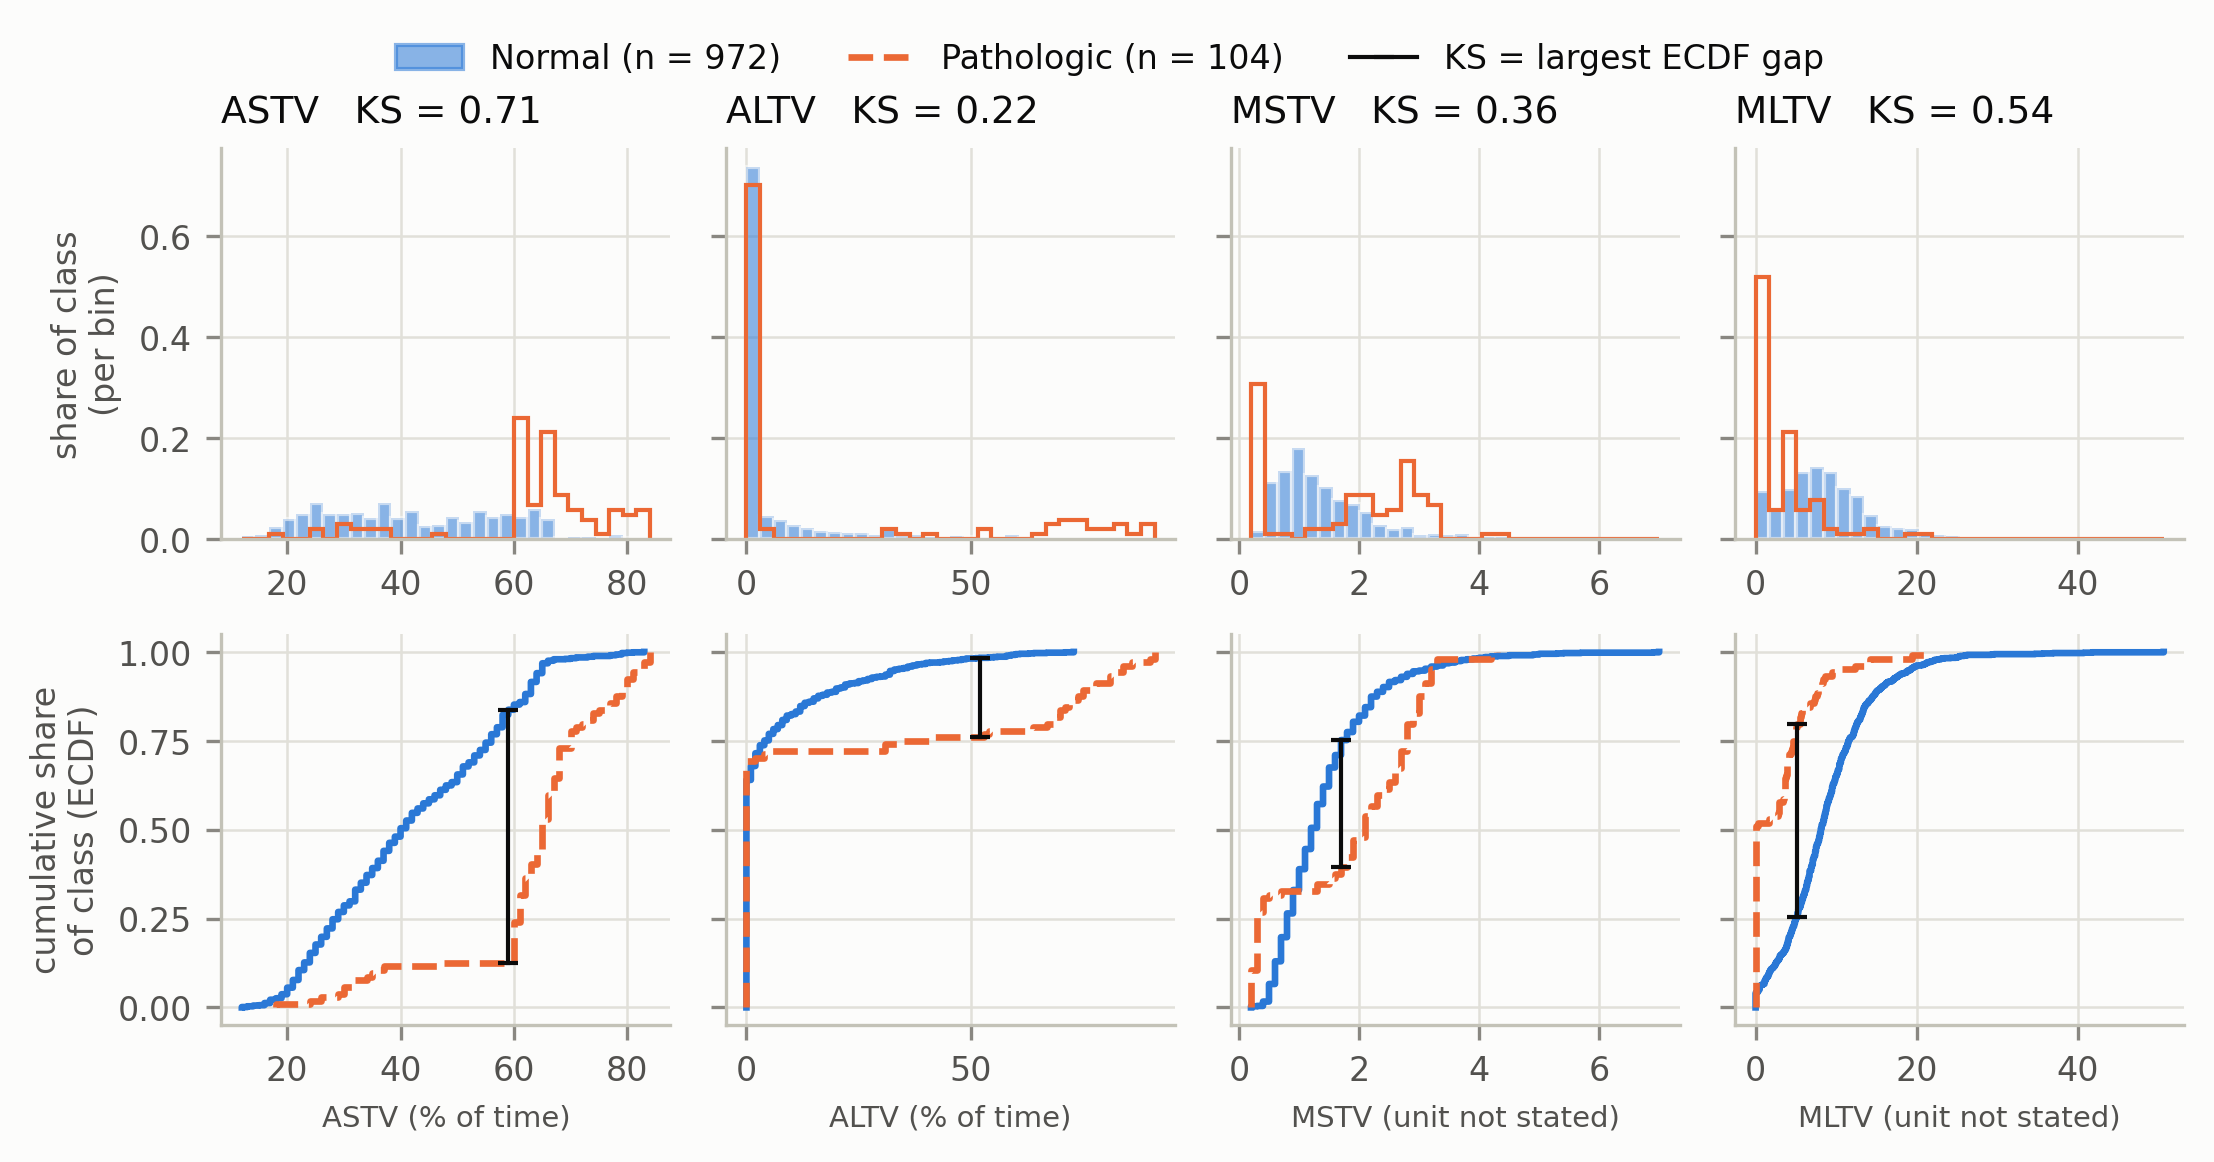

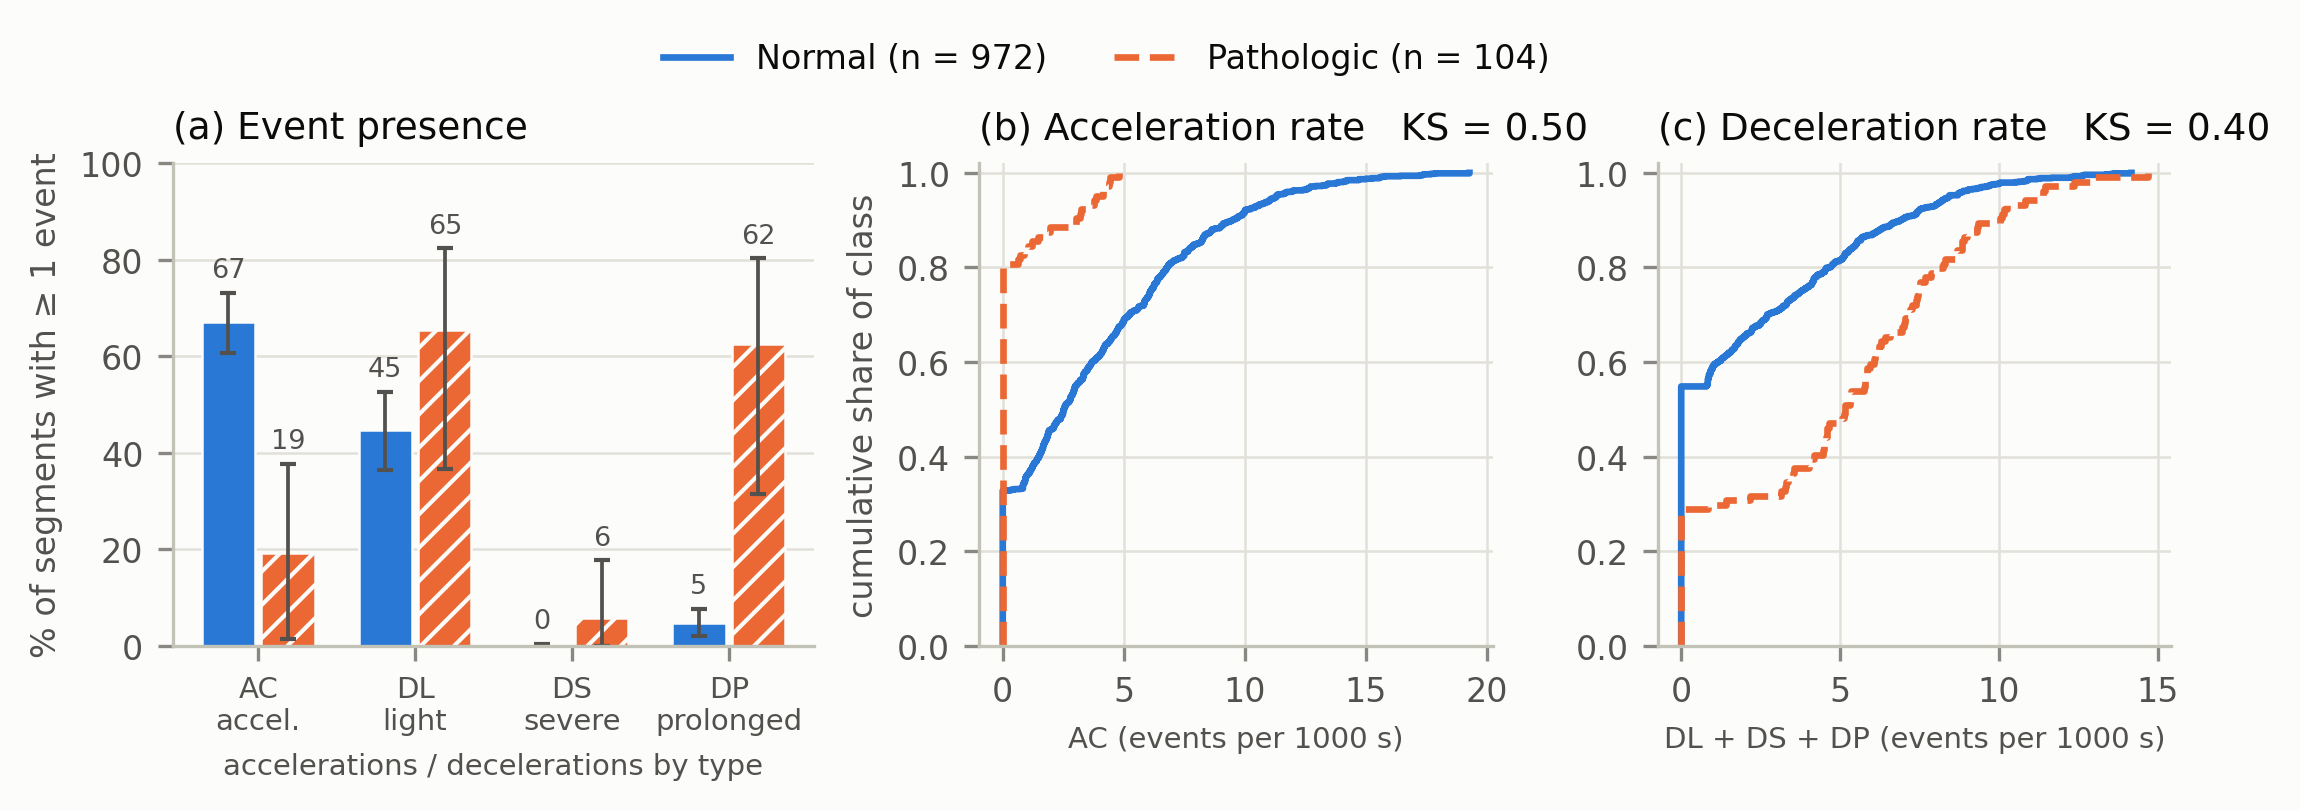

In [3]:
display(Image(str(p2_eda.FIG / "fig1_variability_contrast.png"), width=900))
display(Image(str(p2_eda.FIG / "fig2_events_contrast.png"), width=900))

In [4]:
R["presence"]

,feature,class,n,n_with_event,share_with_event,ci_lo,ci_hi
0,AC,Normal,972,653,0.672,0.606,0.732
1,AC,Pathologic,104,20,0.192,0.013,0.377
2,DL,Normal,972,435,0.448,0.364,0.526
3,DL,Pathologic,104,68,0.654,0.367,0.824
4,DS,Normal,972,1,0.001,0.000,0.003
5,DS,Pathologic,104,6,0.058,0.000,0.177
6,DP,Normal,972,46,0.047,0.020,0.077
7,DP,Pathologic,104,65,0.625,0.315,0.803
8,FM,Normal,972,320,0.329,0.255,0.414
9,FM,Pathologic,104,67,0.644,0.492,0.802


### Pathologic segments are not one population

Splitting Pathologic rows by `DP > 0` (a label-conditioned, descriptive split; not clinical subtypes) shows two subgroups that move MSTV, ALTV, Width, Variance and Mean in *opposite* directions. Only ASTV is elevated in both.

,Normal,"Pathologic, DP-absent (DP = 0)","Pathologic, DP-present (DP > 0)"
n_segments,972.000,39.000,65.000
n_exams,158.000,18.000,12.000
LB,132.000,134.000,132.000
AC,0.003,0.000,0.000
DL,0.000,0.000,0.003
DP,0.000,0.000,0.002
ASTV,40.000,71.000,62.000
MSTV,1.200,0.300,2.700
ALTV,0.000,69.000,0.000
MLTV,8.100,3.900,0.000


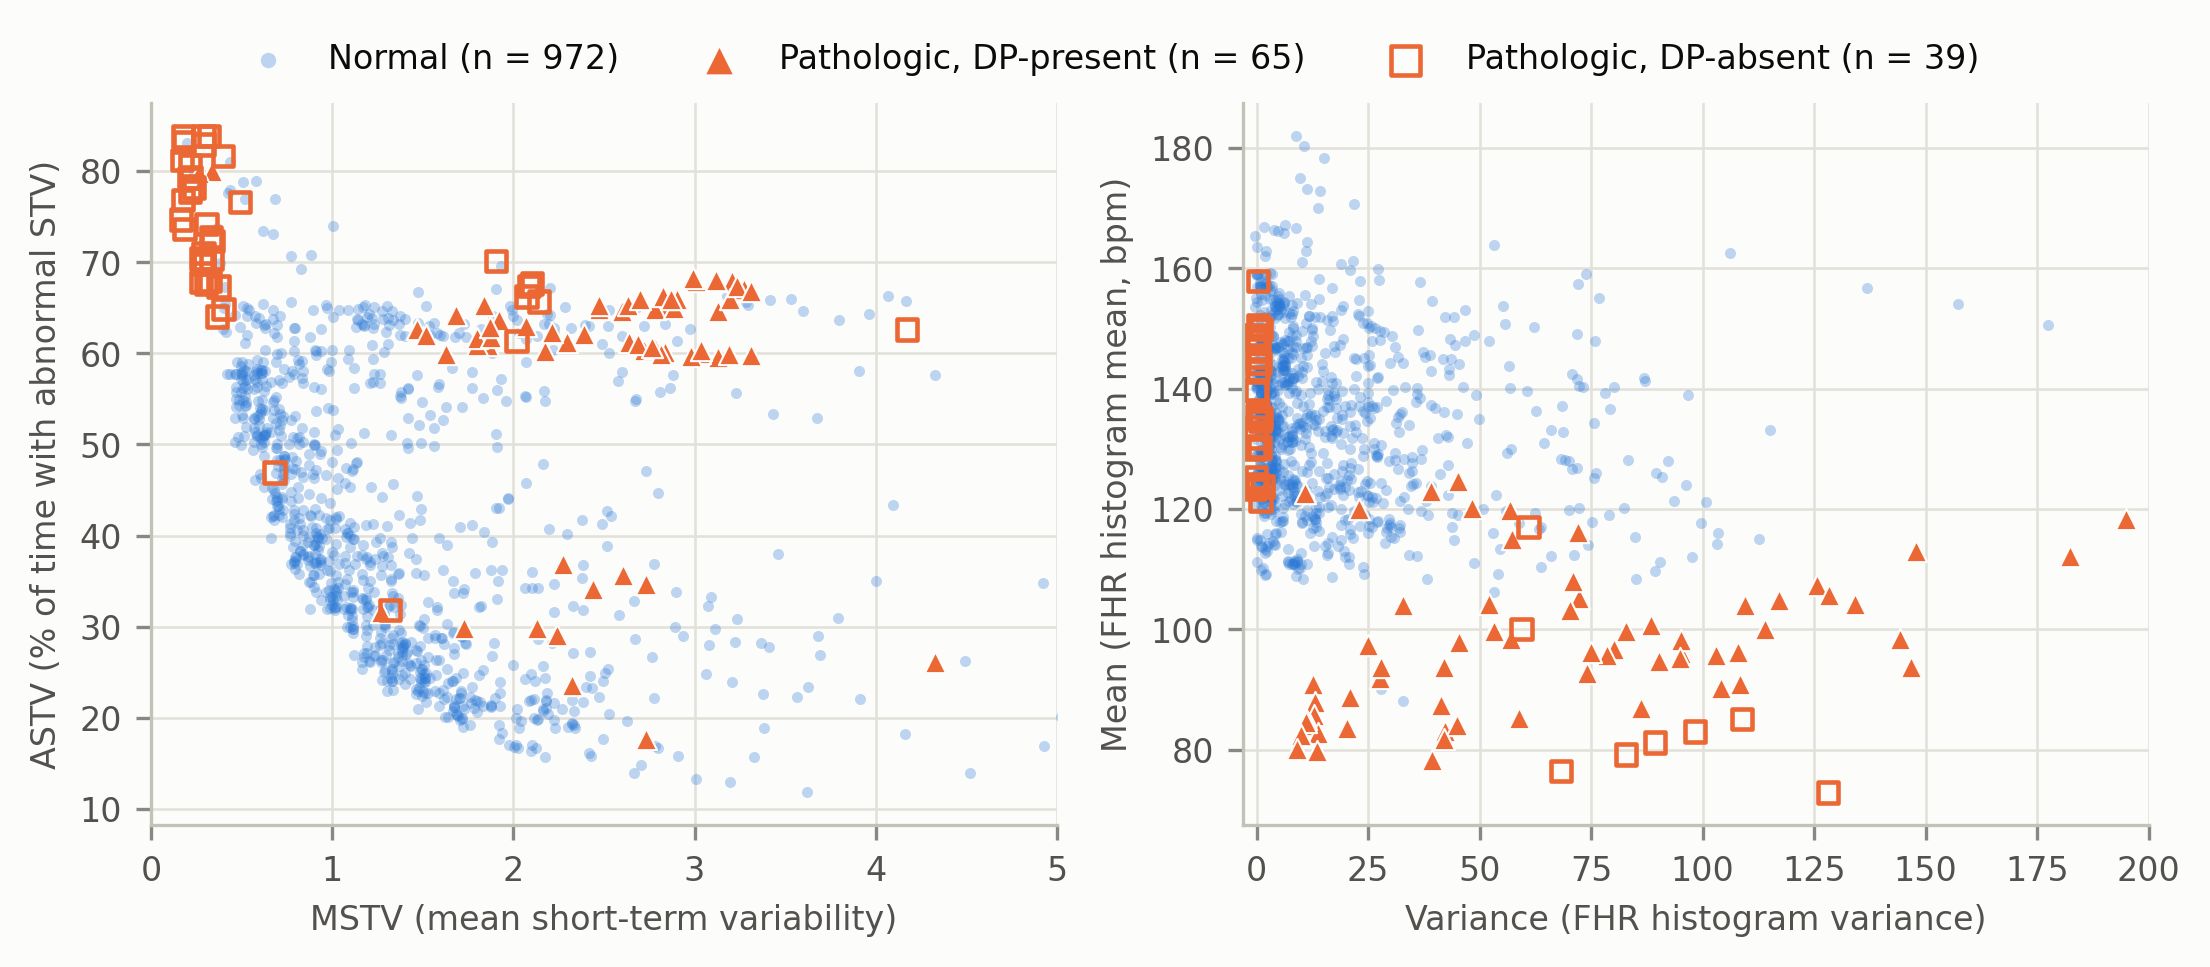

In [5]:
display(R["phenotypes"].T)
display(Image(str(p2_eda.FIG / "fig5_pathologic_phenotypes.png"), width=900))

## 3. Feature separability

* `KS`: two-sample Kolmogorov–Smirnov statistic. For zero-inflated / discrete features it is still a valid distance between ECDFs, but its p-value is not used.
* `AUC_path_gt_normal`: P(x_path > x_normal) + ½P(tie); rank-based and scale-free. `AUC_abs_dev` is the AUROC of |z| w.r.t. the Normal training mean/SD (two-sided view).
* `wasserstein_normalSD`: Wasserstein-1 after scaling by the Normal training SD, so features are comparable; `wasserstein_raw` is in the feature's own unit and must not be ranked across features.
* `MI_knn_nats`: kNN mutual information with the label (mean of 20 seeds); `MI_presence_nats` is the exact MI of the indicator x > 0 for event rates.
* `KS_ci_*`: 95% percentile interval from 2000 **exam-level** bootstrap resamples; `KS_rowboot_*` is the naive row bootstrap, shown only to demonstrate that it is too narrow. `KS_wo_top2` drops the two exams that hold 36 of the 104 Pathologic segments.

In [6]:
cols = ["family", "normal_median", "path_median", "normal_IQR", "path_IQR", "KS", "KS_ci_lo", "KS_ci_hi", "KS_rowboot_lo", "KS_rowboot_hi",
        "KS_wo_top2", "AUC_path_gt_normal", "AUC_abs_dev", "wasserstein_normalSD", "wasserstein_raw", "MI_knn_nats", "MI_presence_nats"]
sep.sort_values("KS", ascending=False)[cols]

,family,normal_median,path_median,normal_IQR,path_IQR,KS,KS_ci_lo,KS_ci_hi,KS_rowboot_lo,KS_rowboot_hi,KS_wo_top2,AUC_path_gt_normal,AUC_abs_dev,wasserstein_normalSD,wasserstein_raw,MI_knn_nats,MI_presence_nats
feature,,,,,,,,,,,,,,,,,
ASTV,variability,4.000e+01,65.000,27.000,9.000,0.712,0.558,0.835,0.639,0.769,0.663,0.861,0.831,1.395,2.133e+01,0.129,NaN
DEC_SEVERE,derived,0.000e+00,0.002,0.000,0.003,0.642,0.364,0.801,0.547,0.729,0.483,0.825,0.825,5.714,1.601e-03,0.145,NaN
DP,events,0.000e+00,0.002,0.000,0.003,0.597,0.292,0.776,0.508,0.685,0.413,0.801,0.801,5.571,1.537e-03,0.133,0.096
Mean,histogram,1.340e+02,103.500,20.000,34.000,0.580,0.293,0.769,0.497,0.672,0.367,0.194,0.796,1.844,2.539e+01,0.143,NaN
MLTV,variability,8.100e+00,0.000,6.600,4.675,0.544,0.439,0.675,0.472,0.628,0.520,0.171,0.733,0.995,5.809e+00,0.087,NaN
Median,histogram,1.380e+02,112.000,20.000,25.500,0.539,0.289,0.739,0.472,0.642,0.390,0.184,0.787,1.643,2.160e+01,0.126,NaN
ACC_DEC,derived,9.524e-04,-0.004,0.006,0.007,0.525,0.464,0.650,0.500,0.572,0.538,0.177,0.650,1.084,5.856e-03,0.084,NaN
AC,events,2.523e-03,0.000,0.006,0.000,0.496,0.336,0.668,0.427,0.570,0.467,0.231,0.567,0.793,3.123e-03,0.055,0.042
Mode,histogram,1.375e+02,117.000,21.000,37.250,0.480,0.288,0.678,0.405,0.578,0.421,0.202,0.740,1.728,2.457e+01,0.126,NaN


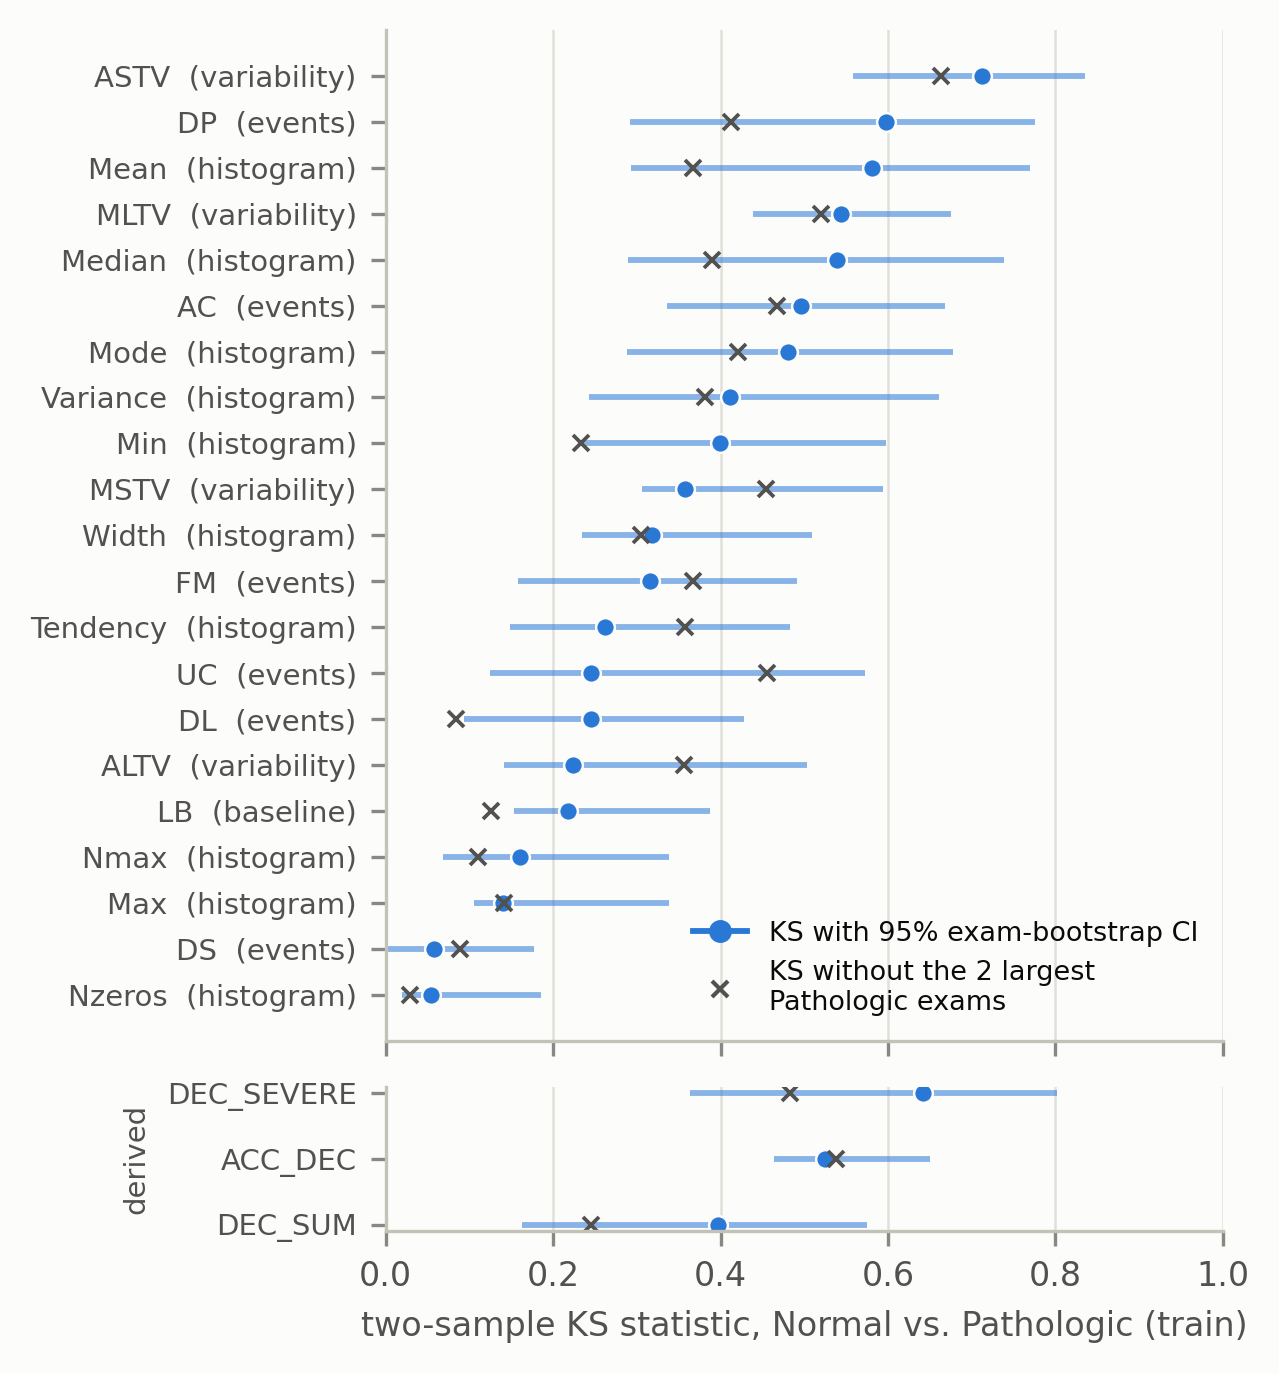

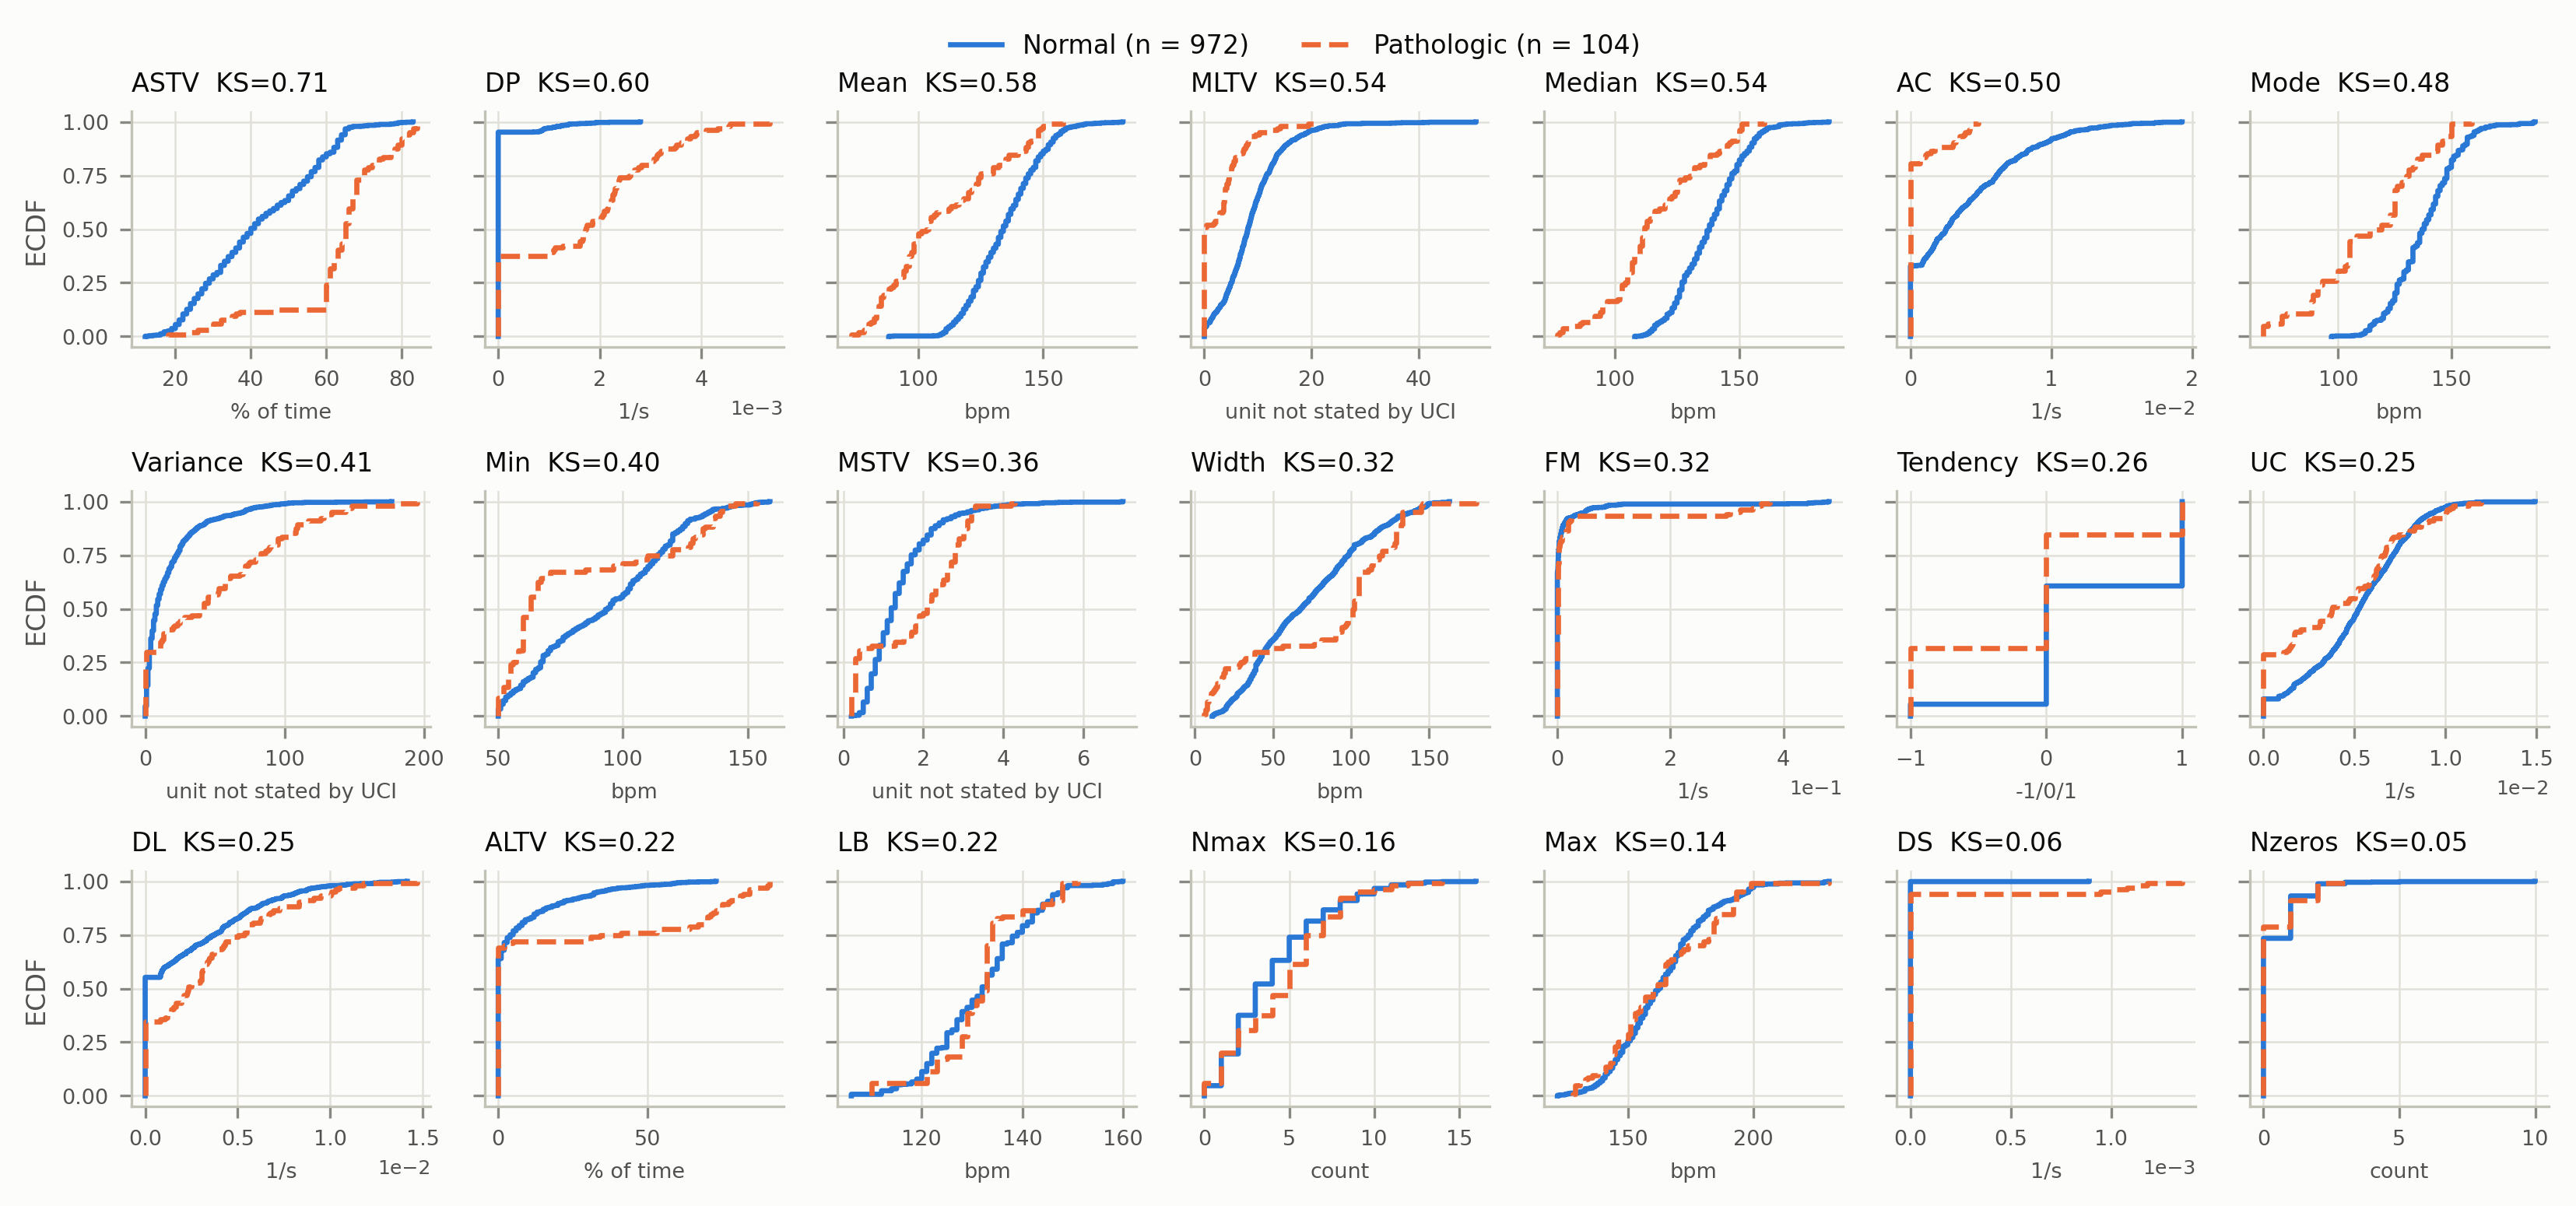

In [7]:
display(Image(str(p2_eda.FIG / "fig3_separability_ranking.png"), width=450))
display(Image(str(p2_eda.FIG / "figS1_all_features_ecdf.png"), width=1000))

## 4. Redundancy

Width == Max - Min on every training row: True


,feature_a,feature_b,spearman_train_all,pearson_train_all,spearman_train_normal,same_family
201,Mode,Median,0.965,0.941,0.963,True
204,Mean,Median,0.943,0.938,0.931,True
200,Mode,Mean,0.900,0.887,0.886,True
165,Width,Min,-0.893,-0.882,-0.885,True
172,Width,Variance,0.820,0.611,0.808,True
17,LB,Median,0.805,0.754,0.861,False
15,LB,Mode,0.793,0.694,0.838,False
167,Width,Nmax,0.783,0.763,0.772,True
180,Min,Variance,-0.734,-0.552,-0.706,True
142,MSTV,Variance,0.728,0.502,0.700,False


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
VIF_normal_train,9.025,3.267,1.127,1.174,4.508,1.168,1.364,1.556,2.537,1.502,2.236,1.000e+12,1.000e+12,1.000e+12,2.436,1.167,14.419,18.258,34.548,2.923,2.843


{
 "threshold_abs_spearman": 0.8,
 "clusters": [
  [
   "Mode",
   "Mean",
   "Median"
  ],
  [
   "Max"
  ],
  [
   "Width",
   "Min"
  ],
  [
   "Variance"
  ],
  [
   "Nmax"
  ],
  [
   "Nzeros"
  ],
  [
   "Tendency"
  ]
 ],
 "kept": [
  "Max",
  "Nmax",
  "Nzeros",
  "Median",
  "Variance",
  "Tendency"
 ],
 "dropped": [
  "Width",
  "Min",
  "Mode",
  "Mean"
 ],
 "lossless": false,
 "note": "Heuristic selection. Width = Max - Min, so dropping Width alone loses nothing; dropping Width AND Min removes Min for good (it is not recoverable from Max alone).",
 "covariance_conditioning_normal_train": {
  "cov_min_eigenvalue_all21": 4.146923426680148e-16,
  "cov_max_eigenvalue_all21": 4.851715053419877,
  "rank_all21": 20
 },
 "linear_r2_of_dropped_from_kept": {
  "Width": 0.8873,
  "Min": 0.7994,
  "Mode": 0.9286,
  "Mean": 0.9434
 }
}


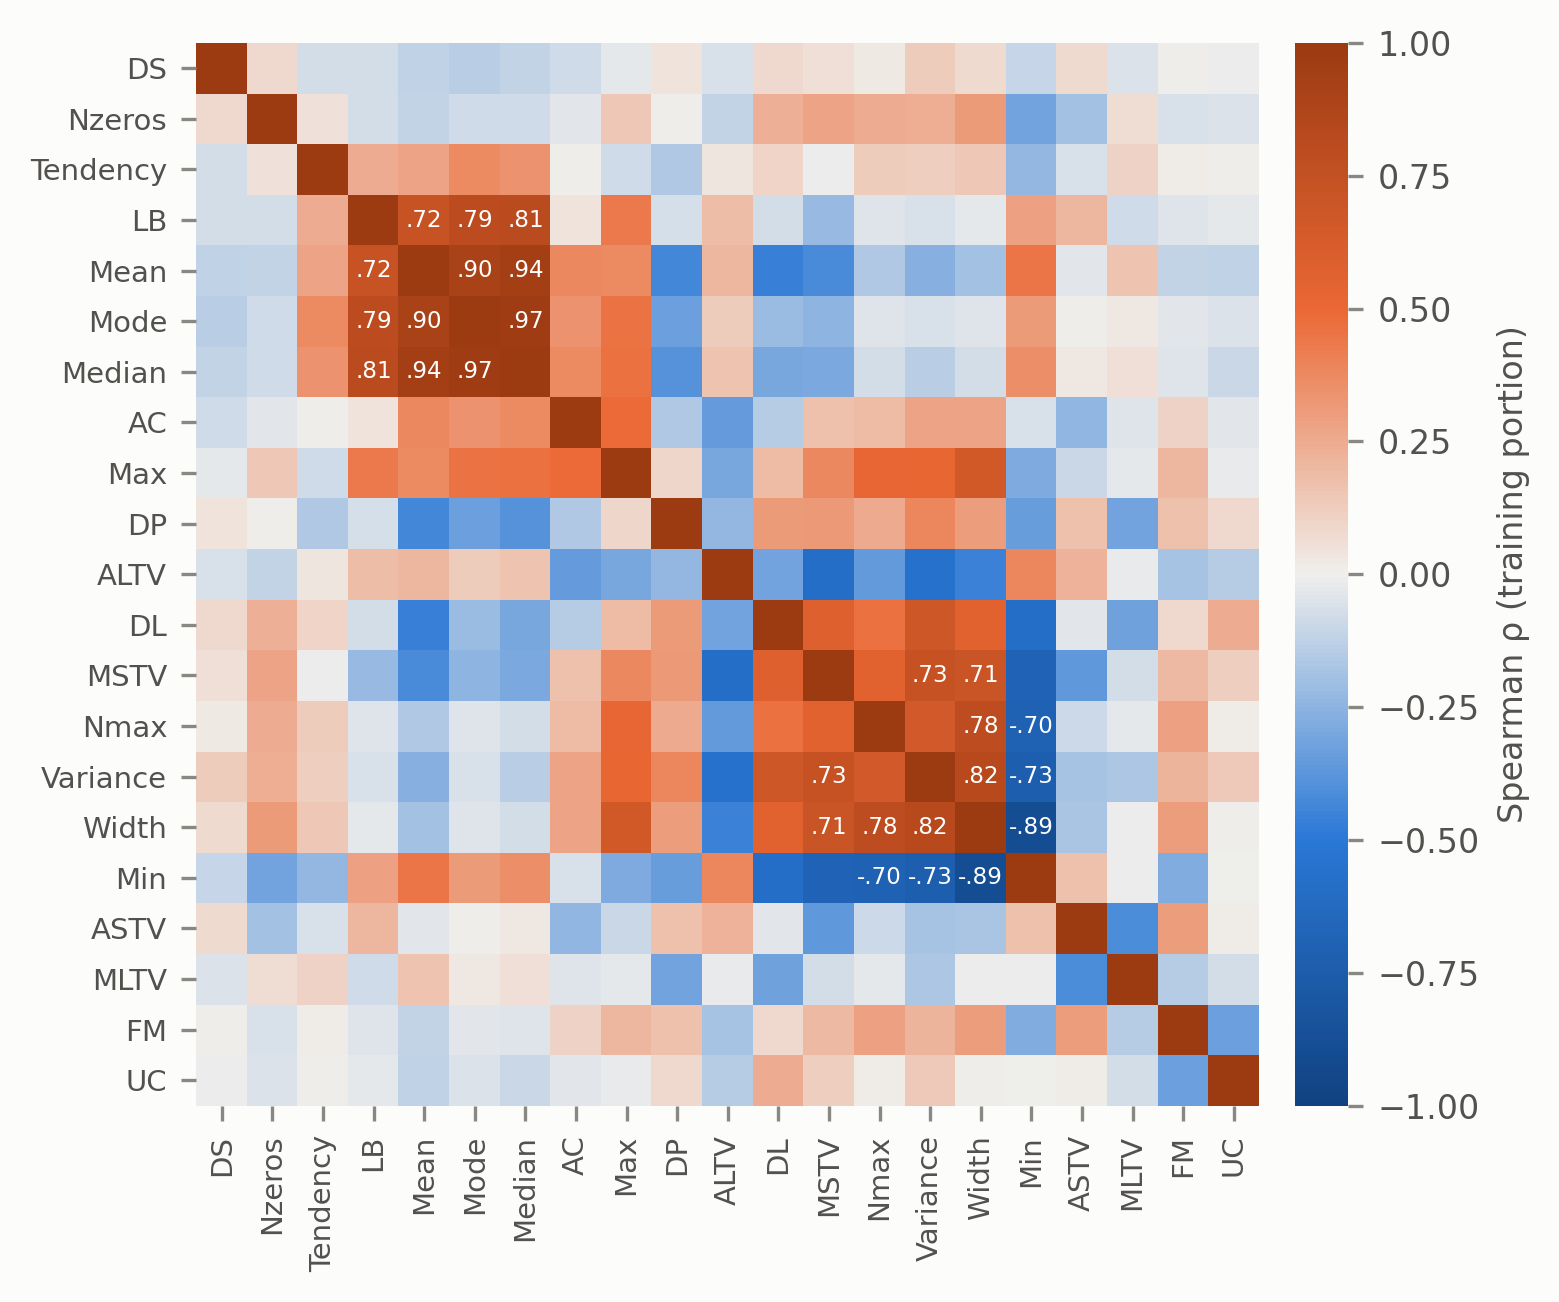

In [8]:
print("Width == Max - Min on every training row:", R["audit"]["width_equals_max_minus_min"])
display(R["pairs"].head(15))
display(R["vif"].to_frame().T)
print(json.dumps(R["pruning"], indent=1))
display(Image(str(p2_eda.FIG / "fig4_spearman_heatmap.png"), width=600))

## 5. Feature-group probe (exploratory, not the P3 model)

Mahalanobis distance to the Normal training distribution (z-score + Ledoit–Wolf covariance fitted on Normal rows of the fitting folds), scored on held-out exams with exam-grouped 5-fold CV **inside the training portion**, repeated 5 times. It only indicates which hypotheses are worth handing to P5; it is not a result for §7–§8. Note that a Mahalanobis score is invariant to adding linear combinations of existing features, so the `+ DEC_SUM` / `+ ACC_DEC` rows are uninformative by construction.

In [9]:
print("Pathologic base rate (PR-AUC of a random scorer):", round(R["probe"].attrs["base_rate"], 4))
R["probe"].drop(columns="features")

Pathologic base rate (PR-AUC of a random scorer): 0.0967


,n_features,AUROC_mean,AUROC_sd,PR_AUC_mean,PR_AUC_sd
feature_set,,,,,
ALL21,21,0.947,0.004,0.647,0.064
variability only (ASTV MSTV ALTV MLTV),4,0.862,0.005,0.372,0.009
events only (AC FM UC DL DS DP),6,0.892,0.002,0.588,0.050
accel/decel only (AC DL DS DP),4,0.850,0.003,0.681,0.017
histogram only (10),10,0.803,0.003,0.420,0.010
baseline only (LB),1,0.361,0.010,0.089,0.002
ALL21 - variability,17,0.853,0.002,0.565,0.063
ALL21 - accel/decel,17,0.933,0.004,0.480,0.027
ALL21 - histogram,11,0.961,0.003,0.696,0.057
